### RaschPy PCM worked example

This notebook works through a sample Rasch analysis of a simulated data set (1,000 persons, 10 items - 4 with a maximum score of 5 and 6 with a maximum score of 3, and no missing data), taking you through the relevant commands step by step, with notes before each cell. Relevant outputs will appear below each cell.

Import the modules and set the working directory (here called `my_working_directory`) to where you want to save your output files.

In [1]:
import raschpy as rp
import os

os.chdir('my_working_directory')

**A note on data validation**

Every model constructor validates the item-response network automatically at instantiation (`validate=True` by default) and warns if it's disconnected — if there's no chain of persons and items linking every item to every other, the resulting item locations aren't on a common scale, even though `calibrate()` will still run without error. This is worth seeing happen once. Here we build a small, deliberately disconnected data set: two groups of persons who each only answer a disjoint set of items, with no item shared between the groups to link them:

In [2]:
sim_disconnected = rp.PCM_Sim(no_of_items=10, no_of_persons=80, max_score_vector=[4] * 10, seed=108)
responses_disconnected = sim_disconnected.responses.copy()
responses_disconnected.iloc[:40, 5:] = float('nan')   # first 40 persons: only answer items 1-5
responses_disconnected.iloc[40:, :5] = float('nan')    # last 40 persons: only answer items 6-10

broken_pcm = rp.PCM(responses_disconnected, [4] * 10)   # raises a UserWarning

/var/folders/hs/f4mv8_3d65bf5fln8jlxhxpc0000gn/T/ipykernel_21133/2303287120.py:6: UserWarning: Unused score categories (item Item_1, category 0: 0 responses; item Item_4, category 0: 0 responses; item Item_4, category 4: 0 responses; item Item_5, category 4: 0 responses; item Item_10, category 0: 0 responses). The thresholds next to these categories are not identified by the data, so their estimates are determined by the smoothing constant rather than the responses. Consider collapsing unused categories (e.g. reducing that item's max_score_vector entry if its top or bottom category is unused) or collecting more data.
  broken_pcm = rp.PCM(responses_disconnected, [4] * 10)   # raises a UserWarning
/Users/markelliott/Documents/GitHub/RaschPy/raschpy/pcm.py:273: UserWarning: The response data is disconnected into 2 separate sub-networks, with no empirical comparisons spanning them: Sub-group 1 (size 5): ['Item_1', 'Item_2', 'Item_3', 'Item_4', 'Item_5']; Sub-group 2 (size 5): ['Item_6', '

`connectivity_status` records the diagnosis, including which items ended up in which isolated sub-group:

In [3]:
broken_pcm.connectivity_status

{'connected': False,
 'components_count': 2,
 'isolated_items': [],
 'all_sub_groups': [['Item_1', 'Item_2', 'Item_3', 'Item_4', 'Item_5'],
  ['Item_6', 'Item_7', 'Item_8', 'Item_9', 'Item_10']],
 'directionally_isolated_items': ['Item_1', 'Item_10', 'Item_4', 'Item_5'],
 'strongly_connected': False}

The rest of this notebook uses a single, fully-connected simulated data set, so this warning won't come up again.

Simulate a data set. Passing `seed=999` makes the simulation fully reproducible — rerunning this notebook will always generate the same data set. 10 items, 1,000 persons, 20% missing data (so each person responds to ~8 items and each item has ~800 responses).

In [4]:
max_score_vector = [5, 5, 5, 5, 3, 3, 3, 3, 3, 3]
sim = rp.PCM_Sim(no_of_items=10, no_of_persons=1000, max_score_vector=max_score_vector, 
                 category_base=1.5, person_sd=2.5, missing=0, seed=999)
sim.responses.to_csv('pcm_scores.csv')

If you have your own response data saved to a CSV file instead of simulating it, use `loadup_pcm()` to load and validate it. Demonstrated here by reloading the file we just saved:

In [5]:
data, invalid_responses = rp.loadup_pcm('pcm_scores.csv', max_score_vector=max_score_vector)

Check the data - view the first two lines

In [6]:
data.head(2)

,Item_1,Item_2,Item_3,Item_4,Item_5,Item_6,Item_7,Item_8,Item_9,Item_10
Person_1,4.0,4.0,4.0,3.0,3.0,3.0,3.0,2.0,2.0,3.0
Person_2,0.0,2.0,3.0,2.0,1.0,0.0,1.0,1.0,0.0,1.0


Check for any invalid responses (not usable for estimation purposes and excluded)

In [7]:
invalid_responses

,Item_1,Item_2,Item_3,Item_4,Item_5,Item_6,Item_7,Item_8,Item_9,Item_10


Create a PCM object. Passing the simulation object `sim` directly (rather than the reloaded `data`) attaches the generating parameters under `pcm.generating`, which lets us check parameter recovery further down, and also means `max_score_vector` doesn't need to be supplied again. If you're analysing your own data, pass a DataFrame and `max_score_vector` instead (e.g. `rp.PCM(data, max_score_vector)`).

In [8]:
pcm = rp.PCM(sim)

Generate item estimates. The `%%time` "magic function" returns the time taken to run the cell contents (algorithm run time in this case).

In [9]:
%%time
pcm.calibrate()

CPU times: user 3.54 ms, sys: 262 μs, total: 3.81 ms
Wall time: 3.69 ms


Check the central item location estimates - view the first two items

In [10]:
pcm.items.head(2)

Item_1    0.624633
Item_2   -0.951019
dtype: float64

Since this is simulated data, we know the true generating item, threshold and person locations, and can check how closely the calibration recovered them using `recovery_stats()`. This produces a recovery plot per parameter type (generating vs. estimated, with identity/OLS/Huber fit lines) and a summary table (RMSE, MAE, bias, Pearson correlation, SD ratio, OLS/Huber regression slopes, an OLS-vs-Huber divergence flag, and the proportion of parameters flagged as significantly different from their generating value) — for items, thresholds, category widths, and persons all in one call. Person recovery uses a pseudo-estimate construction (Elliott & Buttery, 2022a) rather than comparing directly against the true person location — this isolates estimation/model-specification error from the irreducible noise of a single finite response pattern, which a naive true-vs-estimated comparison would otherwise be dominated by. Results are stored in `pcm.recovery` (e.g. `pcm.recovery.items.summary`, `pcm.recovery.thresholds.summary`, `pcm.recovery.category_widths.summary`, `pcm.recovery.persons.summary`).

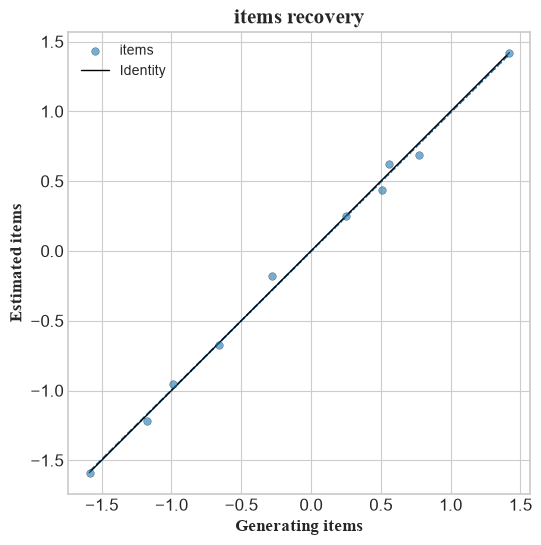

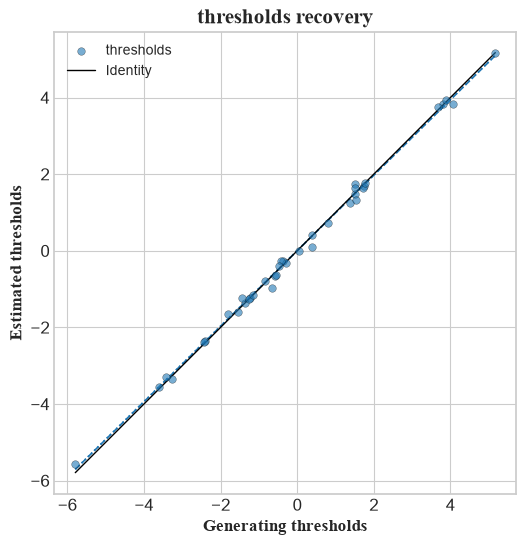

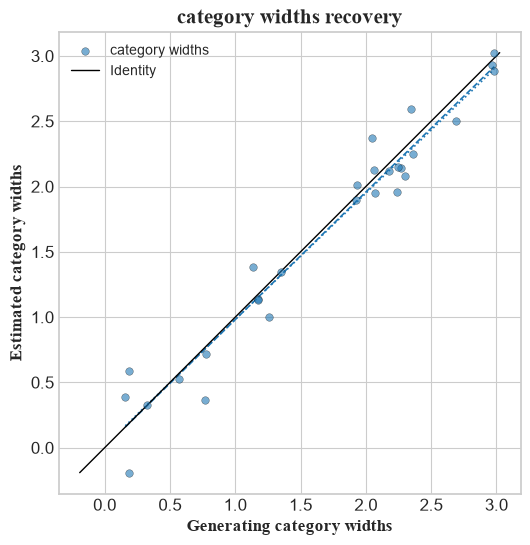

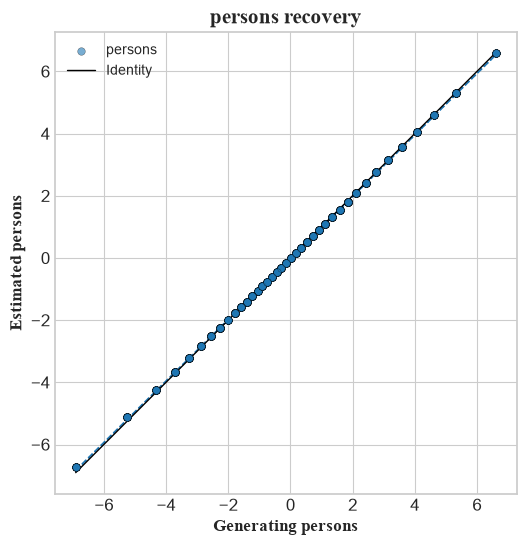

,Overall
RMSE,0.053436
MAE,0.042
bias,-0.001552
r,0.998318
r_squared,0.996638
SD_ratio,0.995776
OLS_slope,0.994101
OLS_intercept,-0.002245
Huber_slope,0.994668
Huber_intercept,-0.004893


In [11]:
pcm.recovery_stats(filename='my_pcm_recovery')
pcm.recovery.items.summary

Generate a table of item statistics (and check run time), and save to file

In [12]:
%%time
pcm.item_stats_df(full=True, filename='pcm_item_stats')

CPU times: user 2.16 ms, sys: 635 μs, total: 2.79 ms
Wall time: 2.45 ms


,Estimate,SE,2.5%,97.5%,Count,Facility,Infit MS,Infit Z,Outfit MS,Outfit Z,PM corr,Exp PM corr
Item_1,0.625,0.045,0.537,0.712,1000,0.438,0.849,-3.235,0.792,-3.505,0.877,0.862
Item_2,-0.951,0.075,-1.097,-0.805,1000,0.581,0.890,-2.531,0.890,-2.536,0.838,0.823
Item_3,0.690,0.045,0.601,0.778,1000,0.433,0.849,-3.137,0.822,-2.396,0.874,0.860
Item_4,1.421,0.065,1.294,1.548,1000,0.374,0.871,-2.945,0.872,-2.645,0.848,0.831
Item_5,-1.588,0.064,-1.714,-1.462,1000,0.681,0.905,-2.029,0.863,-1.637,0.794,0.777
Item_6,0.441,0.052,0.339,0.542,1000,0.440,0.875,-2.494,0.783,-2.295,0.831,0.813
Item_7,-1.220,0.059,-1.335,-1.105,1000,0.640,0.892,-2.231,0.829,-1.657,0.812,0.794
Item_8,0.247,0.052,0.145,0.350,1000,0.461,0.860,-2.965,0.821,-2.403,0.832,0.814
Item_9,-0.671,0.056,-0.780,-0.561,1000,0.584,0.878,-2.735,0.852,-2.623,0.820,0.797
Item_10,-0.182,0.055,-0.289,-0.075,1000,0.528,0.967,-0.696,0.970,-0.452,0.814,0.810


Check the item statistics table

Generate a table of threshold statistics (and check run time), and save to file

In [13]:
%%time
pcm.threshold_stats_df(full=True, filename='pcm_threshold_stats_centred')

CPU times: user 2.98 ms, sys: 677 μs, total: 3.65 ms
Wall time: 3.34 ms


Estimate     SE   2.5%  97.5%  Infit MS  Infit Z  Outfit MS  \
Item_1  1    -1.989  0.130 -2.243 -1.735     1.003    0.084      0.901   
        2    -1.273  0.140 -1.548 -0.998     0.877   -2.440      0.829   
        3    -0.885  0.125 -1.130 -0.640     0.902   -1.967      0.821   
        4     1.014  0.125  0.769  1.259     0.977   -0.461      0.979   
        5     3.131  0.179  2.781  3.481     0.899   -1.293      0.815   
Item_2  1    -4.605  0.357 -5.304 -3.905     0.680   -2.257      0.555   
        2    -2.354  0.159 -2.665 -2.043     0.950   -0.689      0.821   
        3    -0.211  0.105 -0.416 -0.006     0.900   -2.222      0.829   
        4     2.288  0.107  2.078  2.497     0.953   -0.994      0.974   
        5     4.882  0.185  4.519  5.244     0.950   -0.574      1.069   
Item_3  1    -1.479  0.137 -1.748 -1.209     1.007    0.127      0.900   
        2    -1.669  0.153 -1.969 -1.370     0.885   -2.077      0.861   
        3    -1.078  0.126 -1.324 -0.832     0.964   -0.705      0.884   
        4     1.071  0.121  0.834  1.308     0.916   -1.731      0.868   
        5     3.153  0.177  2.806  3.500     1.007    0.111      0.867   
Item_4  1    -3.787  0.140 -4.060 -3.513     0.910   -1.596      0.829   
        2    -2.649  0.108 -2.861 -2.437     1.006    0.139      0.917   
        3     0.278  0.114  0.056  0.501     0.946   -1.086      0.888   
        4     2.406  0.187  2.041  2.772     0.860   -1.723      0.750   
        5     3.752  0.298  3.168  4.336     0.750   -2.103      0.586   
Item_5  1    -1.973  0.166 -2.298 -1.647     0.890   -1.435      0.830   
        2    -0.019  0.116 -0.246  0.208     0.943   -1.190      0.871   
        3     1.991  0.097  1.800  2.181     0.966   -0.760      0.875   
Item_6  1    -0.709  0.112 -0.928 -0.489     0.958   -0.808      0.845   
        2    -0.340  0.124 -0.583 -0.097     0.901   -2.035      0.870   
        3     1.048  0.120  0.812  1.283     0.938   -1.281      0.853   
Item_7  1    -2.127  0.143 -2.407 -1.846     0.850   -2.231      0.738   
        2     0.899  0.116  0.671  1.126     0.920   -1.601      0.844   
        3     1.227  0.111  1.008  1.445     1.012    0.245      0.906   
Item_8  1    -1.479  0.107 -1.689 -1.270     0.994   -0.126      0.909   
        2     0.476  0.119  0.243  0.708     0.918   -1.650      0.952   
        3     1.004  0.122  0.765  1.243     0.896   -2.069      0.747   
Item_9  1    -1.715  0.137 -1.983 -1.447     0.950   -0.904      0.871   
        2    -0.585  0.108 -0.797 -0.374     0.893   -2.244      0.815   
        3     2.301  0.105  2.095  2.508     0.933   -1.388      0.896   
Item_10 1    -1.459  0.123 -1.700 -1.218     0.959   -0.789      0.867   
        2    -0.456  0.114 -0.679 -0.233     1.090    1.888      1.154   
        3     1.915  0.108  1.703  2.126     0.914   -1.729      0.835   

           Outfit Z  Discrim  PM corr  Exp PM corr  
Item_1  1    -0.551    1.017    0.179        0.174  
        2    -2.347    1.368    0.118        0.094  
        3    -2.168    1.252    0.128        0.104  
        4    -0.265    1.046    0.161        0.157  
        5    -1.158    1.153    0.183        0.171  
Item_2  1    -1.439    1.321    0.142        0.113  
        2    -1.262    1.101    0.162        0.151  
        3    -1.940    1.196    0.270        0.242  
        4    -0.265    1.073    0.276        0.266  
        5     0.387    1.048    0.194        0.197  
Item_3  1    -0.362    1.003    0.157        0.150  
        2    -1.780    1.327    0.102        0.082  
        3    -1.320    1.112    0.117        0.105  
        4    -1.674    1.196    0.198        0.177  
        5    -0.844    1.026    0.157        0.161  
Item_4  1    -1.332    1.178    0.245        0.226  
        2    -0.827    1.011    0.221        0.220  
        3    -1.106    1.095    0.251        0.238  
        4    -1.326    1.199    0.147        0.126  
        5    -1.862    1.437    0.099        0.077  
Item_5  1  

Check the centred threshold statistics table - view the first two thresholds

Check the uncentred threshold statistics table - view the first two items

In [14]:
pcm.threshold_stats_uncentred.to_csv('pcm_threshold_stats_uncentred.csv')
pcm.threshold_stats_uncentred.head(2)

Estimate    SE   2.5%  97.5%  Infit MS  Infit Z  Outfit MS  \
Item_1 1    -1.364  0.13 -1.618 -1.110     1.003    0.084      0.901   
       2    -0.648  0.14 -0.923 -0.373     0.877   -2.440      0.829   

          Outfit Z  Discrim  PM corr  Exp PM corr  
Item_1 1    -0.551    1.017    0.179        0.174  
       2    -2.347    1.368    0.118        0.094

And the same recovery check for the uncentred threshold structure (already computed together with item recovery above, via the same `recovery_stats()` call — its plot appeared alongside the item recovery plot). Since thresholds are per-item, the table is indexed by (threshold position, item) pairs internally:

In [15]:
pcm.recovery.thresholds.summary

,Overall
RMSE,0.126659
MAE,0.095642
bias,-0.0
r,0.998578
r_squared,0.997158
SD_ratio,0.9868
OLS_slope,0.985397
OLS_intercept,-0.0
Huber_slope,0.985858
Huber_intercept,0.006633


`recovery_stats()` also checks category-width recovery (a separate parameter type from raw threshold locations) as a bonus over the old notebook's checks:

In [16]:
pcm.recovery.category_widths.summary

,Overall
RMSE,0.195305
MAE,0.151771
bias,-0.034319
r,0.976218
r_squared,0.953001
SD_ratio,1.000717
OLS_slope,0.976918
OLS_intercept,0.004165
Huber_slope,0.966644
Huber_intercept,0.014975


Generate a table of person statistics (and check run time), and save to file

In [17]:
%%time
pcm.person_stats_df(full=True, filename='pcm_person_stats')

CPU times: user 5.07 ms, sys: 592 μs, total: 5.66 ms
Wall time: 5.5 ms


,Estimate,CSEM,RSEM,Score,Max score,p,Infit MS,Infit Z,Outfit MS,Outfit Z
Person_1,2.404,0.570,0.367,31,38,0.816,0.416,-1.263,0.473,-0.868
Person_2,-1.401,0.426,0.532,11,38,0.289,1.563,1.238,1.219,0.611
Person_3,-5.131,1.063,0.416,1,38,0.026,0.153,-1.251,0.078,-0.216
Person_4,0.160,0.410,0.498,21,38,0.553,1.471,1.061,1.317,0.795
Person_5,1.814,0.518,0.536,29,38,0.763,1.072,0.307,0.920,0.010
...,...,...,...,...,...,...,...,...,...,...
Person_996,-3.668,0.718,0.760,3,38,0.079,1.120,0.393,1.852,1.018
Person_997,1.320,0.480,0.458,27,38,0.711,0.911,-0.034,0.971,0.096
Person_998,-1.785,0.460,0.415,9,38,0.237,0.814,-0.256,0.788,-0.301
Person_999,-6.708,NaN,NaN,0,38,0.000,NaN,NaN,NaN,NaN


Check the person statistics table - view the first ten persons with `.head(10)`

And the same recovery check for person locations (already computed together with item/threshold recovery above, via the same `recovery_stats()` call — its plot appeared alongside the others):

In [18]:
pcm.recovery.persons.summary

,Overall
RMSE,0.036882
MAE,0.026168
bias,-0.001807
r,0.999951
r_squared,0.999902
SD_ratio,0.988879
OLS_slope,0.988831
OLS_intercept,-0.001944
Huber_slope,0.990649
Huber_intercept,-0.005327


Generate a table of test-level statistics (and check run time), and save to file

In [19]:
%%time
pcm.test_stats_df(filename='pcm_test_stats')

CPU times: user 528 μs, sys: 309 μs, total: 837 μs
Wall time: 730 μs


,Items,Thresholds,Persons
Mean,-0.119,-0.000,-0.014
SD,0.966,2.289,2.453
Separation ratio,16.800,15.356,4.848
Strata,22.733,20.808,6.797
Reliability,0.996,0.996,0.959


Check the test statistics table

Run a residual correlation analysis (and check run time), and save relevant output to file

In [20]:
%%time
pcm.res_corr_analysis()
pcm.residual_correlations.to_csv('pcm_residual_correlations.csv')
pcm.loadings.to_csv('pcm_loadings.csv')

CPU times: user 5.4 ms, sys: 1.72 ms, total: 7.12 ms
Wall time: 8.16 ms


View the table of pairwise standard residual correlations

In [21]:
round(pcm.residual_correlations, 3)

,Item_1,Item_2,Item_3,Item_4,Item_5,Item_6,Item_7,Item_8,Item_9,Item_10
Item_1,1.000,-0.086,-0.196,-0.084,-0.153,-0.157,-0.132,-0.143,-0.124,-0.096
Item_2,-0.086,1.000,-0.132,-0.093,-0.116,-0.090,-0.138,-0.106,-0.101,-0.115
Item_3,-0.196,-0.132,1.000,-0.190,-0.114,-0.096,-0.062,-0.144,-0.112,-0.122
Item_4,-0.084,-0.093,-0.190,1.000,-0.096,-0.140,-0.104,-0.055,-0.105,-0.129
Item_5,-0.153,-0.116,-0.114,-0.096,1.000,-0.097,-0.096,-0.004,-0.095,-0.078
Item_6,-0.157,-0.090,-0.096,-0.140,-0.097,1.000,-0.092,-0.132,-0.061,-0.096
Item_7,-0.132,-0.138,-0.062,-0.104,-0.096,-0.092,1.000,-0.094,-0.083,-0.108
Item_8,-0.143,-0.106,-0.144,-0.055,-0.004,-0.132,-0.094,1.000,-0.098,-0.149
Item_9,-0.124,-0.101,-0.112,-0.105,-0.095,-0.061,-0.083,-0.098,1.000,-0.094
Item_10,-0.096,-0.115,-0.122,-0.129,-0.078,-0.096,-0.108,-0.149,-0.094,1.000


View the item loadings on the first principal component of the pairwise standard residual correlations (dimensionality test)

In [22]:
round(pcm.loadings['PC 1'], 3)

Item_1    -0.170
Item_2    -0.038
Item_3     0.250
Item_4    -0.229
Item_5     0.023
Item_6     0.120
Item_7     0.072
Item_8    -0.087
Item_9     0.023
Item_10    0.047
Name: PC 1, dtype: float64

Produce an item characteristic curve (item response function) curve for Item 2, with observed category means plotted and the thresholds marked

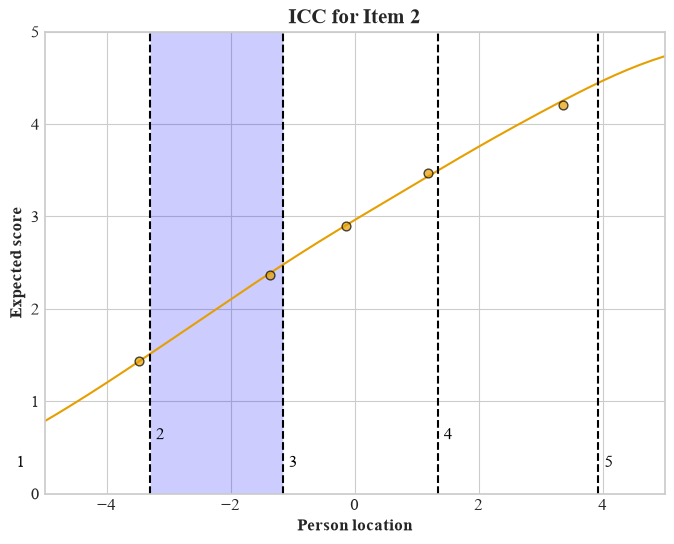

In [23]:
pcm.icc('Item_2', title='ICC for Item 2', obs=True, thresh_lines=True, cat_highlight=2, xmin=-5, xmax=5, filename='my_pcm_icc')

Produce category response curves for Item 2, with the central item location marked

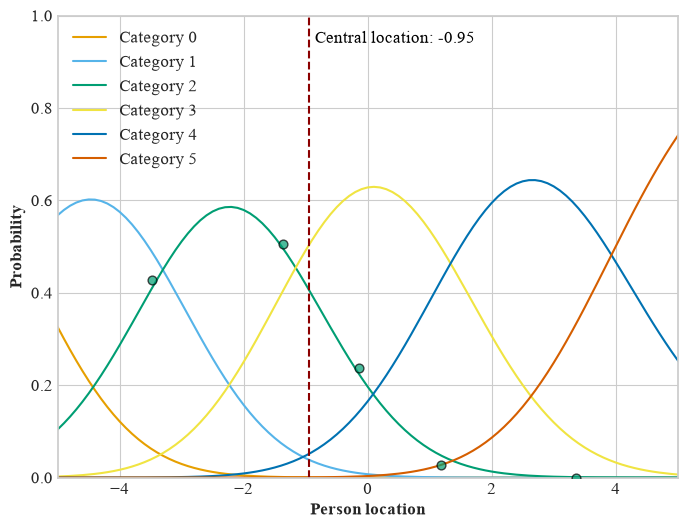

In [24]:
pcm.crcs('Item_2', central_location=True, obs=[2], xmin=-5, xmax=5, filename='my_pcm_crcs')

Produce threshold characteristic curves for Item 2, with observed category means plotted for threshold 2 and the central item location marked

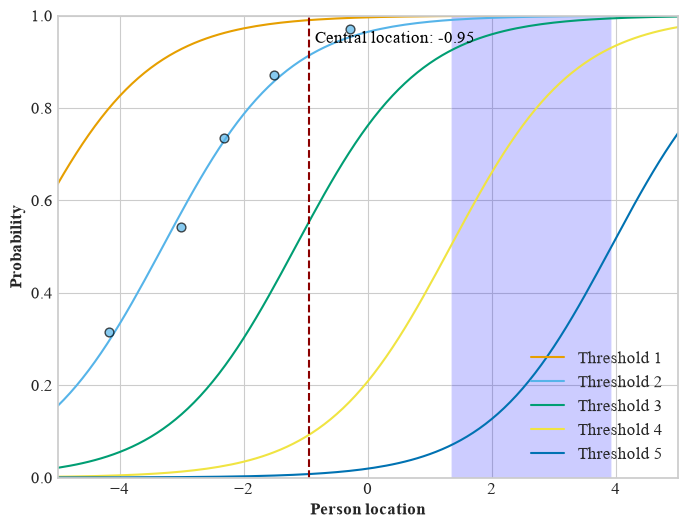

In [25]:
pcm.threshold_ccs('Item_2', central_location=True, obs=[2], cat_highlight=4, xmin=-5, xmax=5, filename='my_pcm_threshold_ccs')

Produce an item information function curve for Item 2

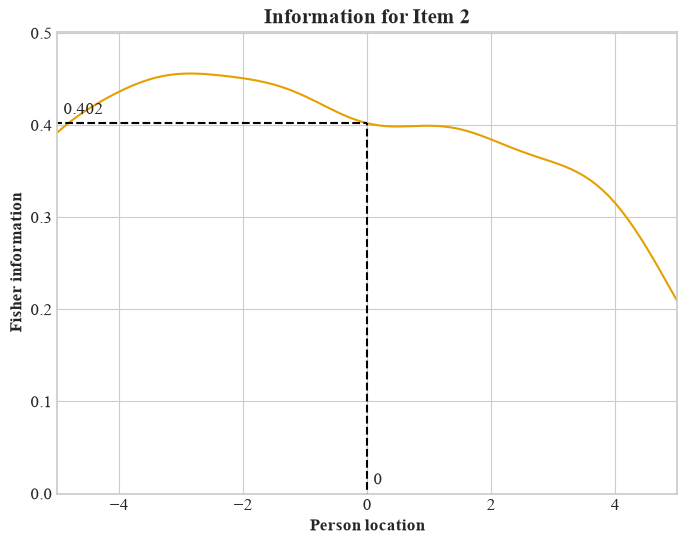

In [26]:
pcm.iic('Item_2', point_info_lines=[0], point_info_labels=True, title='Information for Item 2', xmin=-5, xmax=5, filename='my_pcm_iic')

Produce a test characteristic curve (test response function), with person locations corresponding to scores of 15 and 25 plotted.

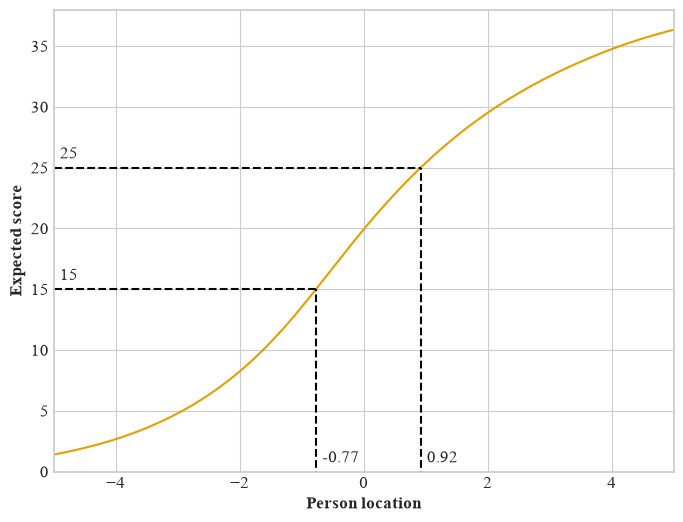

In [27]:
pcm.tcc(score_lines=[15, 25], score_labels=True, filename='my_pcm_tcc')

Produce a test information curve

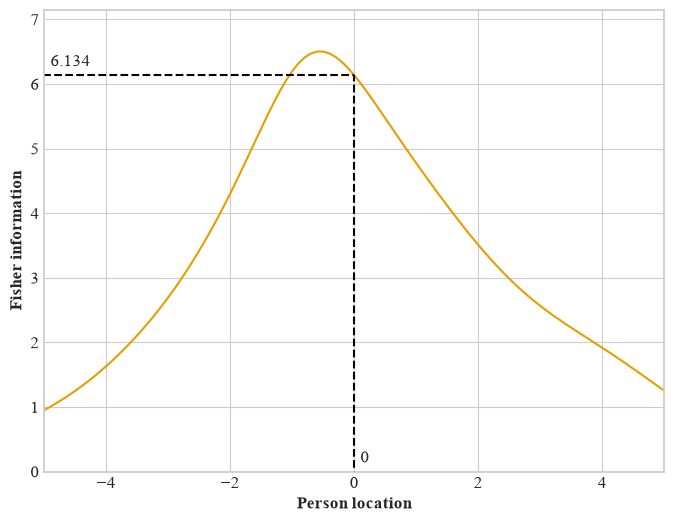

In [28]:
pcm.test_info(point_info_lines=[0], point_info_labels=True, filename='my_pcm_test_info_curve')

Produce a test CSEM (conditional standard error of measurement) curve, with the CSEM corresponding to a person location of -3 plotted

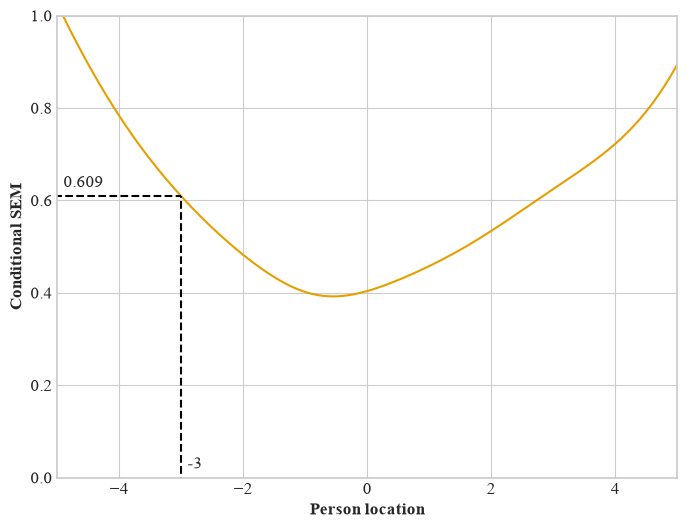

In [29]:
pcm.test_csem(point_csem_lines=[-3], point_csem_labels=True, ymax=1, filename='my_pcm_csem_curve')

Produce a histogram of standardised residuals, with a normal distribution curve overlaid

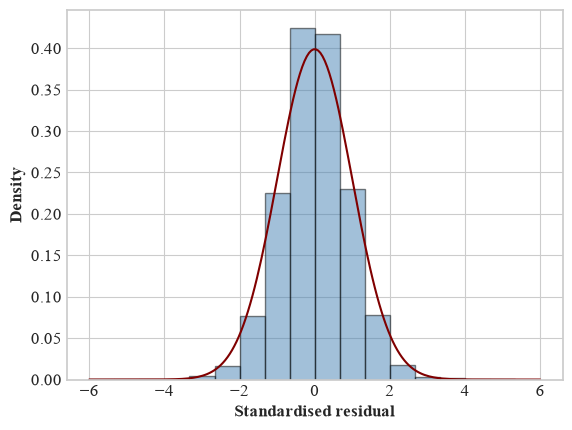

In [30]:
pcm.std_residuals_plot(bin_width=0.6, normal=True, filename='my_pcm_std_residuals_plot')

Produce a Wright map, showing the person location distribution alongside an item strip (one row per item, divided into its own category segments at each Rasch-Andrich threshold), with mean/±1SD/±2SD reference marks for persons

/Users/markelliott/Documents/GitHub/RaschPy/raschpy/base.py:4294: UserWarning: Disordered thresholds for item(s) Item_3. Only categories that are most probable for some range of the trait shown. For more detailed inspection of threshold structure, run self.crcs() plot and/or self.threshold_stats_df().
  warnings.warn(


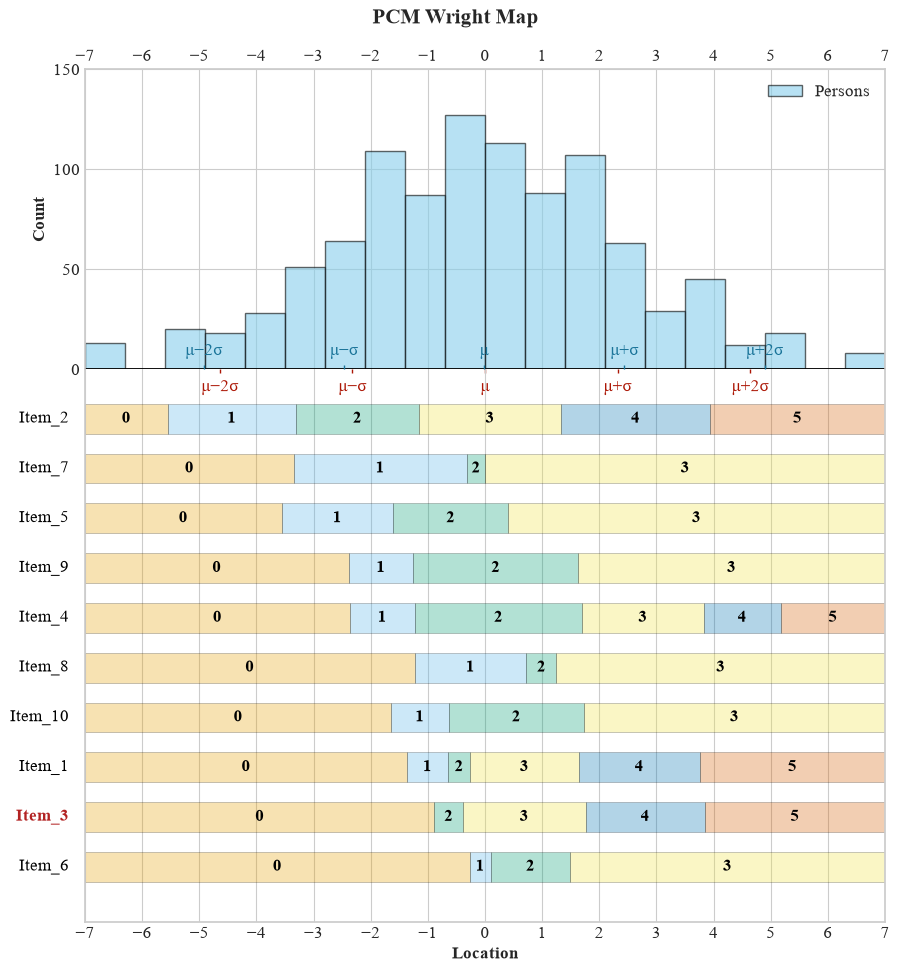

In [31]:
pcm.wright_map(item_strip=True, distribution_markers=True, title='PCM Wright Map', filename='my_pcm_wright_map')

In [32]:
help(rp.PCM.wright_map)

Help on function wright_map in module raschpy.base:

wright_map(self, model=None, person_names=None, item_names=None, facet_element_names=None, expand_model=False, show_stretch=True, item_level='items', threshold_type='rasch-andrich', orientation='vertical', map_type='hist', item_labels=False, item_strip=False, item_distribution=False, facet_labels=False, overlay_facet=False, strip_thickness=2.0, strip_alpha=0.3, sort='location', palette='colorblind multi', neutral_extremes=False, item_row_height=None, facet_row_height=None, narrow_font=False, edge_padding=0.5, distribution_markers=False, group_by=None, group_colors=None, stack=True, blend=False, prop=False, person_lim=None, item_lim=None, facet_lim=None, person_scaling=None, facet_scaling=1, no_of_bins=20, pad=False, plot_range=None, kde_points=500, bw_method='scott', line_width=1, figsize=None, title=None, plot_style='white', edge_color='black', person_color='skyblue', item_color='salmon', facet_color='mediumseagreen', person_line_co